# MRI Brain Tumor Classification — Transfer Learning & Overfitting Prevention

This notebook trains and compares **two MobileNetV2 transfer-learning configurations** for four classes:

- Glioma
- Meningioma
- No Tumor
- Pituitary

It demonstrates:
- Data augmentation
- Dropout
- Early stopping
- Model checkpoints
- ReduceLROnPlateau
- L2 regularization
- Learning curves for diagnosing overfitting/underfitting
- A comparison of two configurations

**Important:** This is an educational machine-learning project, not a medical diagnostic tool. The dataset has only Train and Val splits; the validation set is used for model selection, so it is not an independent final test set.

## 1. Install dependencies (only if needed)

If TensorFlow, pandas, and matplotlib are already installed in your notebook environment, skip this cell. On a fresh Vast.ai instance, you may need to install them first.

In [1]:
# Uncomment and run only if the packages are missing:
# %pip install -q tensorflow pandas matplotlib scikit-learn

## 2. Imports and configuration

**Check `DATASET_ROOT` before running the notebook.**

Expected layout (matching the structure discussed earlier):

```text
data/raw/
├── Train/
│   ├── Glioma/
│   │   ├── images/   # MRI images
│   │   └── labels/   # bounding-box label files; ignored by this notebook
│   ├── Meningioma/
│   ├── No Tumor/
│   └── Pituitary/
└── Val/
    ├── Glioma/
    ├── Meningioma/
    ├── No Tumor/
    └── Pituitary/
```

The loader looks inside each class's `images/` folder when one exists. If there is no `images/` folder, it looks for images directly inside that class folder. It ignores label files and reads only common image extensions.

In [2]:
from pathlib import Path
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
INITIAL_EPOCHS = 20

# Change this if your dataset is stored somewhere else in Jupyter.
# Example: Path("/workspace/IRM/data/raw")
DATASET_ROOT = Path("../data/raw")

TRAIN_DIR = DATASET_ROOT / "Train"
VAL_DIR = DATASET_ROOT / "Val"

CLASS_NAMES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Dataset root:", DATASET_ROOT.resolve())
print("Train directory exists:", TRAIN_DIR.exists())
print("Validation directory exists:", VAL_DIR.exists())

TensorFlow: 2.21.0
GPU devices: []
Dataset root: C:\workspace\projects\IRM\data\raw
Train directory exists: True
Validation directory exists: True


## 3. Find image files and assign labels

Each image receives a numeric label based on `CLASS_NAMES`. The `labels/` directories are not used for this **classification** notebook; those bounding-box labels are for object-detection/localization workflows.

In [3]:
def collect_images(split_dir, split_name):
    split_dir = Path(split_dir)
    if not split_dir.exists():
        raise FileNotFoundError(
            f"Cannot find {split_name} directory: {split_dir.resolve()}\n"
            "Update DATASET_ROOT in the configuration cell."
        )

    records = []
    missing_classes = []

    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        if not class_dir.exists():
            missing_classes.append(str(class_dir))
            continue

        images_dir = class_dir / "images"
        search_dir = images_dir if images_dir.exists() else class_dir

        for file_path in search_dir.rglob("*"):
            if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "filepath": str(file_path.resolve()),
                    "class_name": class_name,
                    "label": CLASS_NAMES.index(class_name),
                    "split": split_name
                })

    if missing_classes:
        raise FileNotFoundError(
            "These class folders were not found:\n" + "\n".join(missing_classes)
        )

    return pd.DataFrame(records)

train_df = collect_images(TRAIN_DIR, "train")
val_df = collect_images(VAL_DIR, "val")

if train_df.empty or val_df.empty:
    raise ValueError("No images found. Check the dataset folder structure and extensions.")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("\nTraining counts:")
print(train_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))
print("\nValidation counts:")
print(val_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))

Training images: 4737
Validation images: 512

Training counts:
class_name
Glioma        1153
Meningioma    1449
No Tumor       711
Pituitary     1424
Name: count, dtype: int64

Validation counts:
class_name
Glioma        136
Meningioma    140
No Tumor      100
Pituitary     136
Name: count, dtype: int64


## 4. Basic data checks

This checks that all four classes have images and that the exact same file path was not accidentally included in both splits. It does **not** detect visually identical copies stored under different filenames; perceptual duplicate checking is a separate task.

In [4]:
assert set(train_df["class_name"].unique()) == set(CLASS_NAMES), "A training class is missing."
assert set(val_df["class_name"].unique()) == set(CLASS_NAMES), "A validation class is missing."

train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
same_paths = train_paths.intersection(val_paths)

print("Exact file paths shared by train and validation:", len(same_paths))
if same_paths:
    print("WARNING: shared paths found. Review them before training.")
else:
    print("No identical file paths appear in both splits.")

display(pd.DataFrame({
    "split": ["train", "validation"],
    "images": [len(train_df), len(val_df)]
}))

Exact file paths shared by train and validation: 0
No identical file paths appear in both splits.


,split,images
0,train,4737
1,validation,512


## 5. Build TensorFlow datasets

Images are decoded and resized to 224 × 224. Labels are integer IDs, so the model will use `sparse_categorical_crossentropy`.

MobileNetV2 expects pixels scaled to approximately `[-1, 1]`; we do this **inside the model** with a `Rescaling` layer. Do not also apply `preprocess_input` to the dataset, or you would preprocess twice.

In [5]:
def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)  # pixel values remain in [0, 255] here
    label = tf.cast(label, tf.int32)
    return image, label

def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_dataset = make_dataset(train_df, training=True)
val_dataset = make_dataset(val_df, training=False)

images_batch, labels_batch = next(iter(train_dataset))
print("Image batch shape:", images_batch.shape)
print("Label batch shape:", labels_batch.shape)
print("Pixel range before model rescaling:",
      float(tf.reduce_min(images_batch)), "to", float(tf.reduce_max(images_batch)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range before model rescaling: 0.0 to 255.0


## 6. View a few training images

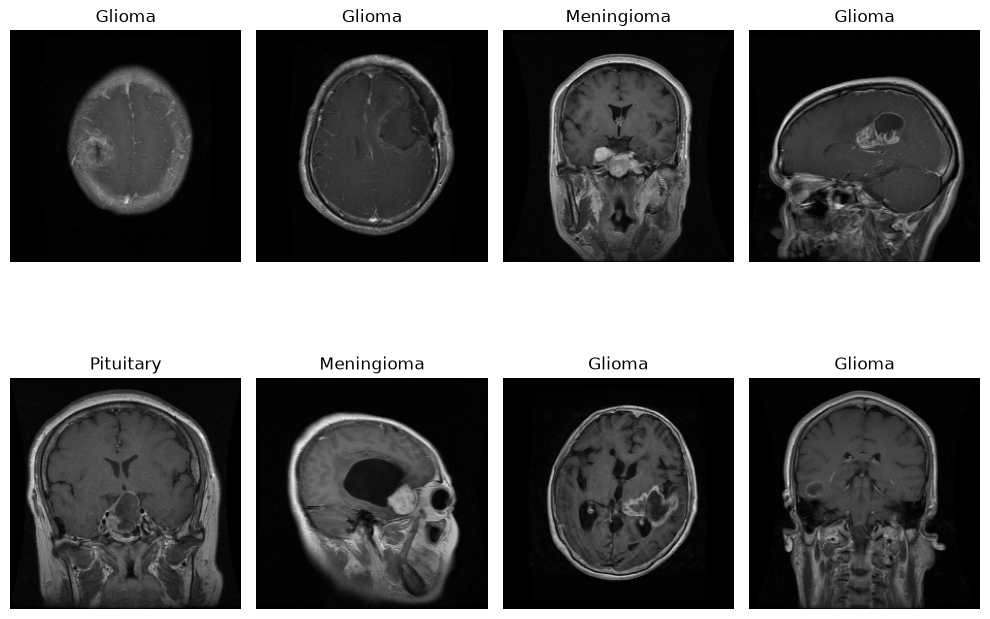

In [6]:
plt.figure(figsize=(10, 8))
for i in range(min(8, images_batch.shape[0])):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(tf.cast(images_batch[i], tf.uint8).numpy())
    plt.title(CLASS_NAMES[int(labels_batch[i].numpy())])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Create the augmentation pipeline

Augmentation is active **only during training**. Validation images are not randomly transformed.

The transformations are intentionally mild. For medical images, augmentation should preserve meaningful anatomy and labels; review sample augmented images and adjust these choices if needed.

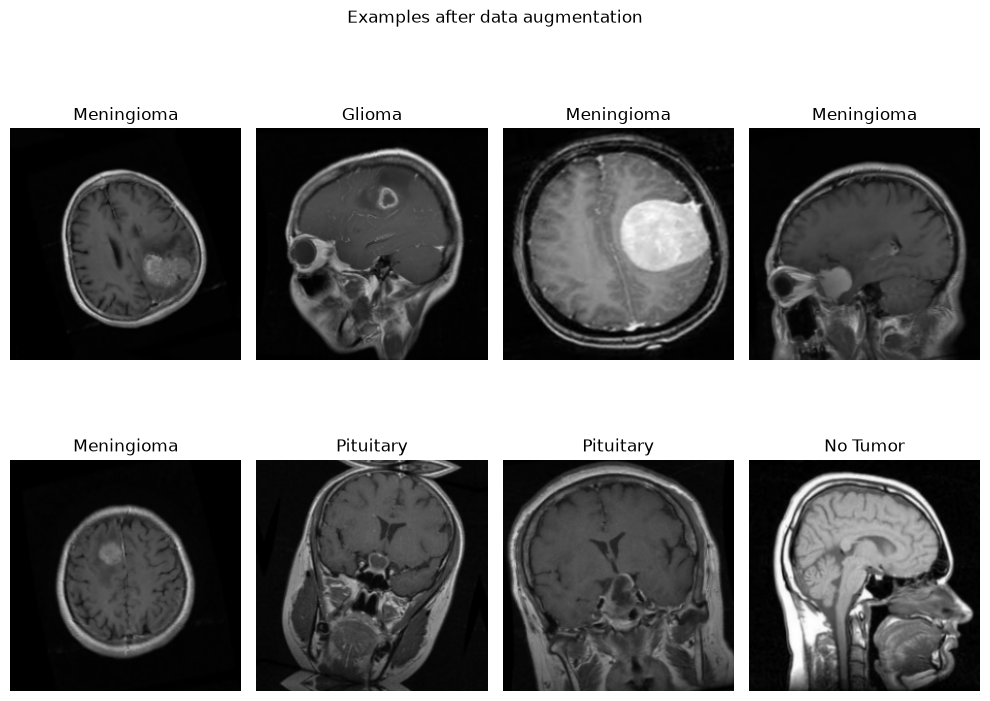

In [7]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.10),
    ],
    name="data_augmentation"
)

# Visualize augmented examples.
sample_images, sample_labels = next(iter(train_dataset))
augmented_images = data_augmentation(sample_images[:8], training=True)

plt.figure(figsize=(10, 8))
for i in range(min(8, augmented_images.shape[0])):
    ax = plt.subplot(2, 4, i + 1)
    # Display original-looking image values; augmentation happens before rescaling.
    plt.imshow(tf.cast(tf.clip_by_value(augmented_images[i], 0, 255), tf.uint8).numpy())
    plt.title(CLASS_NAMES[int(sample_labels[i].numpy())])
    plt.axis("off")
plt.suptitle("Examples after data augmentation")
plt.tight_layout()
plt.show()

## 8. Build a transfer-learning model

We use MobileNetV2 pretrained on ImageNet and remove its original classification head (`include_top=False`). At first, its weights are frozen. The new classification head learns the four MRI classes.

We will compare two configurations:

- **Configuration A — baseline regularization:** augmentation + Dropout 0.3, no L2 penalty.
- **Configuration B — stronger regularization:** same augmentation + Dropout 0.5 + L2 regularization on the new Dense layers.

Both configurations use the same data split and callbacks. This makes the comparison more meaningful, although small random variations can still affect results.

In [8]:
def build_model(dropout_rate=0.3, l2_strength=0.0):
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False

    regularizer = (
        tf.keras.regularizers.l2(l2_strength)
        if l2_strength > 0
        else None
    )

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="image")
    x = data_augmentation(inputs)
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1, name="mobilenetv2_rescaling")(x)

    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizer,
        name="classifier_dense"
    )(x)
    x = tf.keras.layers.Dropout(dropout_rate, name="classifier_dropout")(x)
    outputs = tf.keras.layers.Dense(
        len(CLASS_NAMES),
        activation="softmax",
        kernel_regularizer=regularizer,
        name="predictions"
    )(x)

    model = tf.keras.Model(inputs, outputs)
    return model, base_model

model_a, base_model_a = build_model(dropout_rate=0.3, l2_strength=0.0)
model_a.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_rescaling           │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 9. Configure callbacks

- **EarlyStopping:** stops if validation loss does not improve for several epochs and restores the best weights.
- **ModelCheckpoint:** saves the model with the best validation loss.
- **ReduceLROnPlateau:** reduces the learning rate if validation loss stops improving.

These callbacks help control training; they do not guarantee that overfitting will never occur.

In [9]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def make_callbacks(run_name):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(OUTPUT_DIR / f"{run_name}_best.keras"),
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            mode="min",
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            mode="min",
            verbose=1
        )
    ]

## 10. Train Configuration A

The pretrained MobileNetV2 layers are frozen. Only the newly added classification layers are trainable.

If your labels are integer class IDs, `sparse_categorical_crossentropy` is the correct loss function.

In [10]:
model_a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_a = model_a.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=INITIAL_EPOCHS,
    callbacks=make_callbacks("config_a"),
    verbose=1
)

Epoch 1/20


c:\workspace\projects\IRM\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.7867 - loss: 0.5653
Epoch 1: val_loss improved from None to 0.49251, saving model to outputs\config_a_best.keras

Epoch 1: finished saving model to outputs\config_a_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 52s 296ms/step - accuracy: 0.7868 - loss: 0.5652 - val_accuracy: 0.7891 - val_loss: 0.4925 - learning_rate: 0.0010
Epoch 2/20
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.8655 - loss: 0.3657
Epoch 2: val_loss improved from 0.49251 to 0.48913, saving model to outputs\config_a_best.keras

Epoch 2: finished saving model to outputs\config_a_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 31s 211ms/step - accuracy: 0.8655 - loss: 0.3656 - val_accuracy: 0.7988 - val_loss: 0.4891 - learning_rate: 0.0010
Epoch 3/20
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.8830 - loss: 0.3050
Epoch 3: val_loss did not improve from 0.48913
149/149 ━━━━━━━━━━━━━━━━━━━━ 29s 197ms/step - accuracy: 0.8830 - loss: 0.3050 - val_accuracy: 0.8

## 11. Train Configuration B

This run starts with a fresh MobileNetV2 instance and compares stronger regularization: Dropout 0.5 and L2 strength `1e-4`. We keep the pretrained base frozen in both runs so that the main comparison is about regularization rather than mixing in fine-tuning.

In [ ]:

tf.keras.backend.clear_session()

model_b, base_model_b = build_model(dropout_rate=0.5, l2_strength=1e-4)

model_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_b = model_b.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=INITIAL_EPOCHS,
    callbacks=make_callbacks("config_b"),
    verbose=1
)


Epoch 1/20
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - accuracy: 0.7582 - loss: 0.6530
Epoch 1: val_loss improved from None to 0.49107, saving model to outputs\config_b_best.keras

Epoch 1: finished saving model to outputs\config_b_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 72s 443ms/step - accuracy: 0.7583 - loss: 0.6530 - val_accuracy: 0.8164 - val_loss: 0.4911 - learning_rate: 0.0010
Epoch 2/20
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.8444 - loss: 0.4378
Epoch 2: val_loss improved from 0.49107 to 0.47443, saving model to outputs\config_b_best.keras

Epoch 2: finished saving model to outputs\config_b_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 81s 435ms/step - accuracy: 0.8444 - loss: 0.4379 - val_accuracy: 0.8242 - val_loss: 0.4744 - learning_rate: 0.0010
Epoch 3/20
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.8672 - loss: 0.3765
Epoch 3: val_loss improved from 0.47443 to 0.40592, saving model to outputs\config_b_best.keras

Epoch 3: finished saving model to o

## 12. Plot learning curves and compare configurations

How to read the curves:

- **Possible overfitting:** training loss keeps decreasing / training accuracy keeps increasing, while validation loss rises or validation accuracy stalls or drops.
- **Possible underfitting:** training and validation performance are both poor, and both curves stop improving.
- **Potentially good fit:** training and validation metrics improve and remain reasonably close.

Do not diagnose from accuracy alone. Look at both loss and accuracy, the size of the gap, and the class-wise results.

In [ ]:
def plot_history(history, title):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, hist["loss"], label="Training loss")
    axes[0].plot(epochs, hist["val_loss"], label="Validation loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, hist["accuracy"], label="Training accuracy")
    axes[1].plot(epochs, hist["val_accuracy"], label="Validation accuracy")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_a, "Configuration A: Dropout 0.3, no L2")
plot_history(history_b, "Configuration B: Dropout 0.5, L2 = 1e-4")

In [ ]:
def summarize_history(history, config_name):
    hist = history.history
    best_epoch = int(np.argmin(hist["val_loss"])) + 1
    best_val_loss = float(np.min(hist["val_loss"]))
    best_val_accuracy = float(np.max(hist["val_accuracy"]))
    last_train_accuracy = (hist["accuracy"][-1])
    last_val_accuracy = float(hist["val_accuracy"][-1])

    return {
        "configuration": config_name,
        "epochs_run": len(hist["loss"]),
        "best_epoch_by_val_loss": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_accuracy_seen": best_val_accuracy,
        "last_train_accuracy": last_train_accuracy,
        "last_val_accuracy": last_val_accuracy,
        "last_train_val_accuracy_gap": last_train_accuracy - last_val_accuracy
    }

comparison = pd.DataFrame([
    summarize_history(history_a, "A: Dropout 0.3, no L2"),
    summarize_history(history_b, "B: Dropout 0.5, L2=1e-4")
])
display(comparison.sort_values("best_val_loss"))

## 13. Evaluate the best saved checkpoints

The checkpoint files are saved under `outputs/`. This cell loads each best checkpoint and evaluates it on the validation dataset. Remember: this is still validation performance, not an independent test result.

In [ ]:
best_model_a = tf.keras.models.load_model(OUTPUT_DIR / "config_a_best.keras")
best_model_b = tf.keras.models.load_model(OUTPUT_DIR / "config_b_best.keras")

eval_a = best_model_a.evaluate(val_dataset, verbose=0, return_dict=True)
eval_b = best_model_b.evaluate(val_dataset, verbose=0, return_dict=True)

display(pd.DataFrame([
    {"configuration": "A: Dropout 0.3, no L2", **eval_a},
    {"configuration": "B: Dropout 0.5, L2=1e-4", **eval_b}
]))

## 14. Class-wise evaluation for the better validation-loss checkpoint

This creates a confusion matrix and classification report. It helps reveal whether the model performs well for all classes or struggles with one class.

Select the model with the lower best validation loss for this diagnostic. Do not treat the validation set as a final unbiased test set.

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

if eval_a["loss"] <= eval_b["loss"]:
    best_model = best_model_a
    chosen_name = "Configuration A"
else:
    best_model = best_model_b
    chosen_name = "Configuration B"

y_true = np.concatenate([labels.numpy() for _, labels in val_dataset])
probabilities = best_model.predict(val_dataset, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("Selected by validation loss:", chosen_name)
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(7, 7))
display.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title(f"Validation confusion matrix — {chosen_name}")
plt.tight_layout()
plt.show()

## 15. Optional next step: fine-tuning

This notebook compares two regularization configurations while keeping MobileNetV2 frozen. Fine-tuning is a separate experiment: after choosing a promising configuration, you can unfreeze some of MobileNetV2's later layers and continue training with a **much smaller learning rate** (for example, `1e-5` or `1e-6`). Recompile the model after changing `trainable` flags, and keep Batch Normalization layers in inference mode where appropriate.

Do not run fine-tuning automatically until you have reviewed the learning curves and validation results.

## 16. Save your results

The best model checkpoints are in `outputs/`. Keep the notebook, training configuration, and results together so you can reproduce the experiment.

**Suggested analysis to write in your report:**
1. Which configuration had the lower best validation loss?
2. Which had the better validation accuracy?
3. Did either model show a growing train/validation gap?
4. Did EarlyStopping stop training before all epochs?
5. Did ReduceLROnPlateau reduce the learning rate?
6. Which classes were most often confused in the confusion matrix?
7. State clearly that results are based on the validation set and need independent testing before any real-world use.